Cargamos la ROI generada en el Módulo 1 (en gris y en color). El video se usará posteriormente.

In [70]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops

VIDEO_PATH = "../data/raw/Registro A_2.MOV"
ROI_PATH = "../data/reference/roi_A_gray.png"
ROI_RGB_PATH = "../data/reference/roi_A_rgb.png"

roi_gray = cv2.imread(ROI_PATH, cv2.IMREAD_GRAYSCALE)
roi_bgr = cv2.imread(ROI_RGB_PATH)

if roi_gray is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_PATH}")
if roi_bgr is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_RGB_PATH}")

roi_rgb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)

print("ROI gris:", roi_gray.shape)
print("ROI RGB:", roi_rgb.shape)

ROI gris: (130, 320)
ROI RGB: (130, 320, 3)


Se utilizará la ROI cuantizada a 32 niveles (5 bits por canal). Esto será útil para que la GLCM sea mucho más chica y que sus estadísticas sean más estables con pocos píxeles.

In [71]:
NIVELES = 32                    # Puedo cambiar niveles para ver que pasa después si lo paso a 64
paso = 256 // NIVELES          

# Cuantización
roi_cuant = (roi_rgb // paso).astype(np.uint8)
gray_cuant = (roi_gray // paso).astype(np.uint8)

Segmentación de la pupila
Usamos la segmentación por Watershed del módulo 2, ya que fue la que mejor delimitó la pupila. Además, sumamos un cierre morfológico, que según la última tabla del mismo módulo fue de las operaciones que menos modificó la máscara.

A partir de la máscara extraemos el contorno externo de la pupila. Hacemos una función con la segmentación para poder reutilizarla en el video frame a frame.

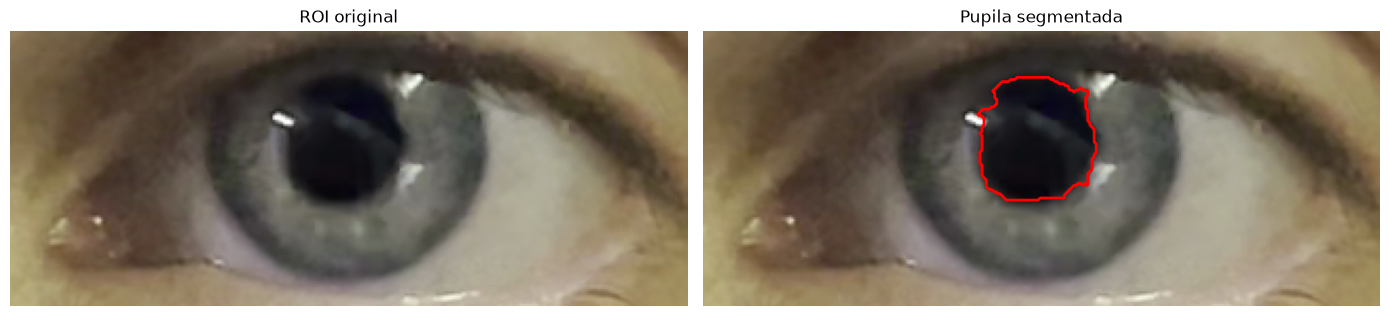

In [72]:
center_x, center_y = 155, 50

def segmentar_pupila(gris, cx=center_x, cy=center_y, radio=20):
    """Segmenta la pupila con Watershed. Devuelve la máscara y su contorno externo"""
    # Hago el contraste + suavizado, tal como se hizo en el módulo 2
    contraste = np.clip(gris.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
    suavizada = cv2.GaussianBlur(contraste, (5, 5), 0)

    # Marcadores: 1 = pupila segura, 2 = fondo seguro (fuera de la elipse)
    marcadores = np.zeros(gris.shape, dtype=np.int32)
    cv2.circle(marcadores, (int(cx), int(cy)), radio, 1, -1)
    zona = np.zeros(gris.shape, dtype=np.uint8)
    cv2.ellipse(zona, (int(cx), int(cy)), (60, 55), 0, 0, 360, 1, -1)
    marcadores[zona == 0] = 2

    ws = cv2.watershed(cv2.cvtColor(suavizada, cv2.COLOR_GRAY2BGR), marcadores)
    mascara = (ws == 1).astype(np.uint8) * 255

    # Cierre morfológico con kernel elíptico de 5x5
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel)

    # Contorno externo de la máscara
    contornos, _ = cv2.findContours(mascara.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contorno = max(contornos, key=cv2.contourArea) if contornos else None
    return mascara, contorno

mask_pupila, contorno = segmentar_pupila(roi_gray)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.title("ROI original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=2)
plt.title("Pupila segmentada")
plt.axis("off")

plt.tight_layout()
plt.show()

A continuación se calculará el área, que representa la cantidad de píxeles de la máscara, el perímetro, que es la longitud del borde de la región, las coordenadas del centroide, la circularidad y la excentricidad.

In [73]:
def descriptores_morfometricos(contorno):
    """Área, perímetro, centroide, circularidad y excentricidad de una máscara binaria."""
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)

    # Centroide a partir de los momentos del contorno
    m = cv2.moments(contorno)
    xc = m["m10"] / m["m00"]
    yc = m["m01"] / m["m00"]

    # Elipse que mejor se ajusta al contorno: de acá salen los ejes y la excentricidad
    elipse = cv2.fitEllipse(contorno)
    (_, _), (d1, d2), angulo = elipse
    eje_mayor, eje_menor = max(d1, d2), min(d1, d2)

    circularidad = 4 * np.pi * area / perimetro**2
    excentricidad = np.sqrt(1 - (eje_menor / eje_mayor) ** 2)

    return {
        "Área (px²)": area,
        "Perímetro (px)": perimetro,
        "Centroide X_c (px)": xc,
        "Centroide Y_c (px)": yc,
        "Circularidad": circularidad,
        "Excentricidad": excentricidad,
        "Eje mayor (px)": eje_mayor,
        "Eje menor (px)": eje_menor,
    }, elipse


desc, elipse = descriptores_morfometricos(contorno)

tabla_morfo = pd.DataFrame(desc, index=["Pupila (frame de referencia)"]).T
display(tabla_morfo.round(4))

,Pupila (frame de referencia)
Área (px²),2543.5000
Perímetro (px),210.6102
Centroide X_c (px),157.2433
Centroide Y_c (px),51.0816
Circularidad,0.7206
Excentricidad,0.3987
Eje mayor (px),60.1142
Eje menor (px),55.1307


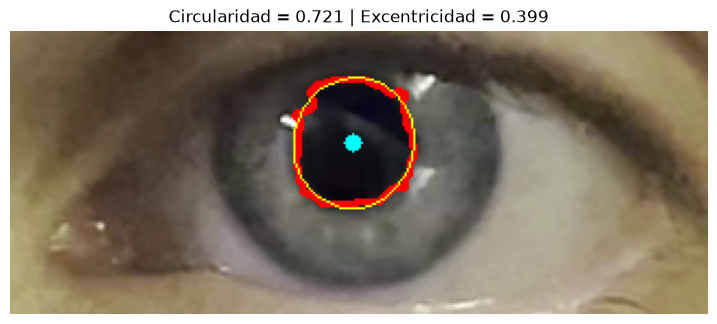

In [74]:
# Visualización: contorno, centroide y elipse ajustada
img = roi_rgb.copy()
cv2.drawContours(img, [contorno], -1, (255, 0, 0), 2)
cv2.ellipse(img, elipse, (255, 255, 0), 1)
cv2.circle(img, (int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))), 4, (0, 255, 255), -1)

plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.title(f"Circularidad = {desc['Circularidad']:.3f} | Excentricidad = {desc['Excentricidad']:.3f}")
plt.axis("off")
plt.show()

Observando los resultados, se observa que el centroide de la pupila segmentada está en (157.2, 51.1), mientras que el centro asignado para aplicar Watershed se colocó en (155, 50), por lo que hay solo una leve diferencia entre estos dos centros.

La circularidad obtenida no es tan cercana a 1 por los bordes irregulares de la segmentación, que igualmente es adecuada para el análisis ya que, como se observa, rodea correctamente la pupila.

Más alla de que la circularidad no fue tan cercana a 1, el tamaño de los ejes de la elipse ajustada indican que la pupila sigue una forma aproximadamente circular.

A continuación, se calculará la media, desvío estándar, entropía y asimetría sobre la ROI de la pupila y el iris en los 3 canales de colores (RGB) de forma independiente.

Para analizar la textura del iris lo segmentamos también por Watershed, con tres marcadores: iris seguro (un anillo cercano a la pupila), pupila segura y fondo seguro (todo lo que queda fuera de una elipse grande). Esta segmentación se usa solo para el análisis de textura del frame de referencia, por lo que no se aplican correcciones adicionales, y se verifica visualmente que sea aproximadamente correcta.

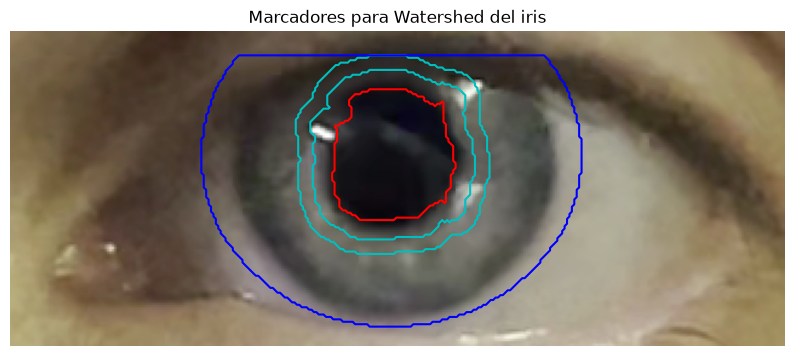

In [75]:
# Parámetros de los marcadores
ANILLO_INT, ANILLO_EXT = 6, 12   # iris "seguro": anillo entre estas dos distancias (px) al borde de la pupila
FONDO_RX, FONDO_RY = 78, 70      # semiejes (px) de la elipse: fuera de ella es fondo seguro
Y_PARPADO = 10                   # filas de arriba de la ROI que se consideran fondo (pestañas / párpado)

cx, cy = int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))

def kernel_elipse(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

marcadores_iris = np.zeros(roi_gray.shape, dtype=np.int32)

# 2 = fondo seguro: fuera de la elipse y en la franja superior
zona = np.zeros(roi_gray.shape, dtype=np.uint8)
cv2.ellipse(zona, (cx, cy), (FONDO_RX, FONDO_RY), 0, 0, 360, 1, -1)
marcadores_iris[zona == 0] = 2
marcadores_iris[:Y_PARPADO, :] = 2

# 1 = iris seguro: anillo cercano a la pupila
anillo_semilla = cv2.subtract(cv2.dilate(mask_pupila, kernel_elipse(ANILLO_EXT)),
                              cv2.dilate(mask_pupila, kernel_elipse(ANILLO_INT)))
marcadores_iris[anillo_semilla > 0] = 1

# 3 = pupila segura (para que el iris no la invada)
marcadores_iris[cv2.erode(mask_pupila, kernel_elipse(2)) > 0] = 3

plt.figure(figsize=(10, 5))
plt.imshow(roi_rgb)
plt.contour(marcadores_iris == 1, colors="c", linewidths=1.5)
plt.contour(marcadores_iris == 2, colors="b", linewidths=1.5)
plt.contour(marcadores_iris == 3, colors="r", linewidths=1.5)
plt.title("Marcadores para Watershed del iris")
plt.axis("off")
plt.show()

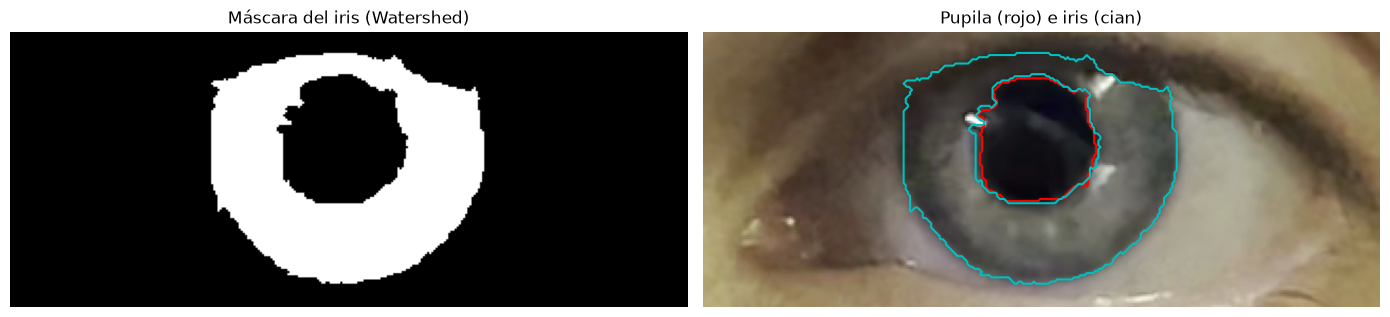

Píxeles de la pupila: 2638
Píxeles del iris:     8393


In [76]:
# Watershed sobre la ROI suavizada
roi_suavizada_iris = cv2.GaussianBlur(roi_gray, (5, 5), 0)
ws_iris = cv2.watershed(cv2.cvtColor(roi_suavizada_iris, cv2.COLOR_GRAY2BGR), marcadores_iris.copy())
mask_iris = (ws_iris == 1).astype(np.uint8) * 255

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask_iris, cmap="gray")
plt.title("Máscara del iris (Watershed)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=1.5)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.title("Pupila (rojo) e iris (cian)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles de la pupila:", cv2.countNonZero(mask_pupila))
print("Píxeles del iris:    ", cv2.countNonZero(mask_iris))

Para evitar errores en los cálculos estadísticos, se deben excluir los reflejos brillantes que se observan en el iris.

Iris: mediana = 85 | percentil 99 = 187 | máximo = 255


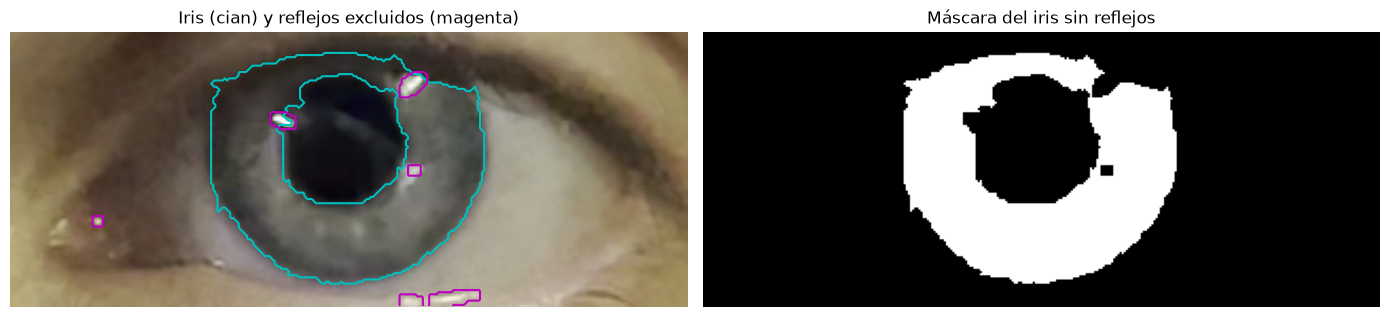

Píxeles del iris antes:   8393
Píxeles del iris después: 8209


In [77]:
UMBRAL_BRILLO = 205   # nivel de gris a partir del cual un píxel se considera reflejo

# Para elegir el umbral: cómo son los valores del iris
valores_iris = roi_gray[mask_iris > 0]
print("Iris: mediana =", int(np.median(valores_iris)), "| percentil 99 =", int(np.percentile(valores_iris, 99)), "| máximo =", int(valores_iris.max()))

# Reflejos: píxeles muy claros, con un pequeño margen alrededor
_, mask_brillo = cv2.threshold(roi_gray, UMBRAL_BRILLO, 255, cv2.THRESH_BINARY)
mask_brillo = cv2.dilate(mask_brillo, np.ones((5, 5), np.uint8))

# Iris sin reflejos
mask_iris_sin_brillo = cv2.bitwise_and(mask_iris, cv2.bitwise_not(mask_brillo))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.contour(mask_brillo > 0, colors="m", linewidths=1.5)
plt.title("Iris (cian) y reflejos excluidos (magenta)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_iris_sin_brillo, cmap="gray")
plt.title("Máscara del iris sin reflejos")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles del iris antes:  ", cv2.countNonZero(mask_iris))
print("Píxeles del iris después:", cv2.countNonZero(mask_iris_sin_brillo))

La entropía mide la proporción de píxeles de la región en cada nivel de gris, mientras que la asimetría es positiva si la distribución tiene una cola hacia valores altos y negativa si la tiene hacia valores bajos.

In [78]:
def estadisticas_primer_orden(img_cuant, mascara, niveles=NIVELES):
    """Media, desvío, entropía y asimetría de cada canal (R, G, B), solo dentro de la máscara."""
    medias, desvios = cv2.meanStdDev(img_cuant, mask=mascara)

    filas = {}
    for i, canal in enumerate("RGB"):
        # Entropía (en bits) a partir del histograma de los niveles cuantizados
        hist = cv2.calcHist([img_cuant], [i], mascara, [niveles], [0, niveles]).ravel()
        p = hist / hist.sum()
        p = p[p > 0]
        entropia = -np.sum(p * np.log2(p))

        # Asimetría (skewness) de los valores de los píxeles dentro de la máscara
        valores = img_cuant[:, :, i][mascara > 0]
        asimetria = pd.Series(valores).skew()

        filas[canal] = {
            "Media": medias[i, 0],
            "Desvío": desvios[i, 0],
            "Entropía (bits)": entropia,
            "Asimetría": asimetria,
        }
    return pd.DataFrame(filas).T


stats_pupila = estadisticas_primer_orden(roi_cuant, mask_pupila)
stats_iris = estadisticas_primer_orden(roi_cuant, mask_iris_sin_brillo)

print("PUPILA")
display(stats_pupila.round(3))
print("IRIS")
display(stats_iris.round(3))

PUPILA


,Media,Desvío,Entropía (bits),Asimetría
R,2.528,1.740,2.430,2.687
G,2.466,1.808,2.526,2.314
B,3.162,1.593,2.348,2.689


IRIS


,Media,Desvío,Entropía (bits),Asimetría
R,10.065,3.129,3.567,0.088
G,9.877,3.280,3.608,-0.037
B,9.197,3.104,3.568,-0.017


La pupila es más oscura y uniforme que el iris: sus medias están entre 2.5 y 3.2, contra cerca de 10 en el iris, y tiene menor desvío y entropía, lo cual es lo esperable, ya que el estroma iridiano presenta más variación de intensidad que la pupila.

La asimetría de la pupila es positiva y alta (2.3 a 2.7), probablemente por el reflejo del flash, que no se excluyó en esa región. En el iris es casi nula, por lo que la distribución de intensidades es aproximadamente simétrica.

Entre canales las diferencias son pequeñas. En la pupila el canal B es algo más claro, y en el iris los tres canales tienen medias, desvíos y entropías muy parecidos.

La GLCM cuenta con qué frecuencia aparece un nivel de gris `i` junto a un nivel `j` a una distancia y dirección dadas. Así describe la relación espacial entre píxeles. Los atributos se calculan por canal y se promedian sobre los 4 ángulos.

In [79]:
DISTANCIAS = [1]
ANGULOS = [0, np.pi/4, np.pi/2, 3*np.pi/4]

def glcm_mascara(canal, mascara, niveles=NIVELES):
    img = canal.copy()
    img[mascara == 0] = niveles                      # nivel extra = "fuera de la región"
    glcm = graycomatrix(img, distances=DISTANCIAS, angles=ANGULOS,
                        levels=niveles + 1, symmetric=True, normed=False)
    glcm = glcm[:niveles, :niveles].astype(float)    # se descarta el nivel de fondo
    glcm /= glcm.sum(axis=(0, 1), keepdims=True)     # se renormaliza
    return glcm

def atributos_glcm(glcm):
    props = {"Contraste": "contrast", "Homogeneidad": "homogeneity",
             "Energía": "energy", "Correlación": "correlation"}
    return {nombre: graycoprops(glcm, p).mean() for nombre, p in props.items()}

In [80]:
glcms = {}
filas_pupila, filas_iris = {}, {}

for idx, canal in enumerate("RGB"):
    img_canal = roi_cuant[:, :, idx]
    glcms[("Pupila", canal)] = glcm_mascara(img_canal, mask_pupila)
    glcms[("Iris", canal)] = glcm_mascara(img_canal, mask_iris_sin_brillo)
    filas_pupila[canal] = atributos_glcm(glcms[("Pupila", canal)])
    filas_iris[canal] = atributos_glcm(glcms[("Iris", canal)])

glcm_pupila = pd.DataFrame(filas_pupila).T
glcm_iris = pd.DataFrame(filas_iris).T

print("GLCM – Pupila")
display(glcm_pupila.round(4))
print("GLCM – Iris")
display(glcm_iris.round(4))

GLCM – Pupila


,Contraste,Homogeneidad,Energía,Correlación
R,0.5549,0.8475,0.3920,0.8966
G,0.5614,0.8448,0.3861,0.9049
B,0.5096,0.8596,0.4192,0.8896


GLCM – Iris


,Contraste,Homogeneidad,Energía,Correlación
R,0.5632,0.8062,0.2094,0.9708
G,0.5485,0.8092,0.2087,0.9741
B,0.5548,0.8070,0.2127,0.9707


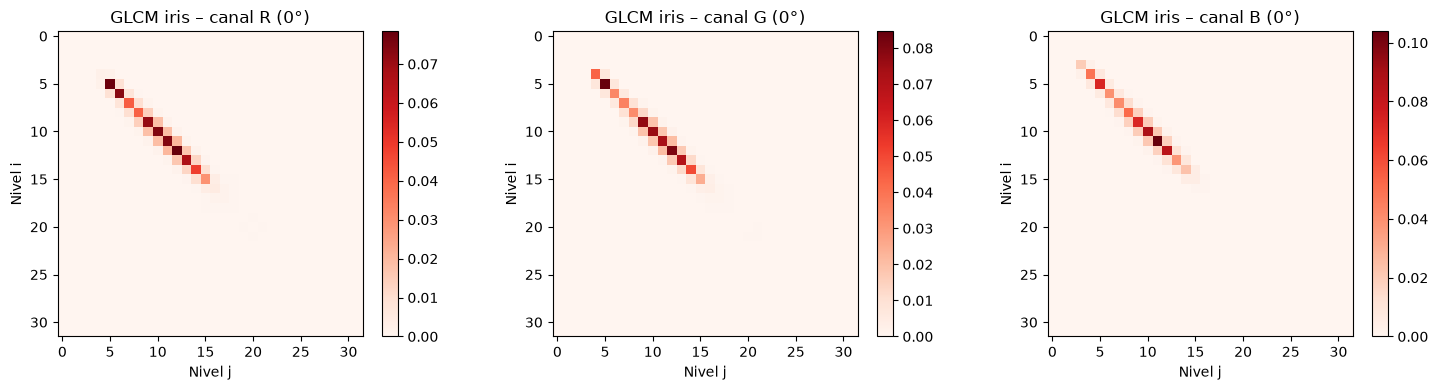

In [81]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, canal in zip(axs, "RGB"):
    im = ax.imshow(glcms[("Iris", canal)][:, :, 0, 0], cmap="Reds")
    ax.set_title(f"GLCM iris – canal {canal} (0°)")
    ax.set_xlabel("Nivel j"); ax.set_ylabel("Nivel i")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

En el iris, los tres canales dan valores de GLCM muy parecidos. Las GLCM de la figura se concentran sobre la diagonal, con niveles de gris vecinos, lo que indica una textura suave, con variaciones graduales entre píxeles. Esto coincide con la correlación y homogeneidad alta.

Entre canales, R muestra mayor contraste (0.563) y menor homogeneidad (0.806). G tiene la energía más baja (0.2087) y la correlación más alta (0.974), y B tiene la mayor energía (0.213), es decir, es el más uniforme. Las diferencias son pcas, por lo que ningún canal aporta una riqueza textural claramente mayor. Sin embargo, podemos decir que R es el más informativo, debido al mayor contraste y menor homogeneidad.

La pupila es más homogénea y tiene mayor energía que el iris, como se espera de una región más uniforme y oscura. Su contraste es similar al del iris, probablemente por los bordes y el brillo que quedaron dentro de la máscara.

A continuación aplicaremos a cada frame del video el mismo procedimiento que se hizo para segmentar la pupila con un solo frame. Esto implica recorte de la ROI, conversión a gris y segmentación de la pupila por Watershed con cierre morfológico.

De cada contorno se obtienen el área y el diámetro.

Para segmentar la pupila en cada frame del video se parte del método del módulo 2 (Watershed sobre la ROI con contraste ×1.5 y suavizado gaussiano de 5x5, marcadores de pupila y de fondo, y cierre morfológico), pero no alcanza con aplicarlo tal cual. En el módulo 2 se trabajó con un único frame de referencia y una ROI fija, mientras que en el video la pupila se mueve, cambia de tamaño y aparecen reflejos del flash y pestañas. Por eso se hicieron algunas modificaciones.

- En el video, el centro de la pupila se estima frame a frame, por lo que se usa una ventana de búsqueda alrededor de la posición del frame anterior y la ROI de 320x130 px se recorta centrada en ese punto.
- Los píxeles muy brillantes cercanos a la pupila se detectan, se dilatan y se rellenan con los píxeles de alrededor.
- El marcador de pupila segura pasa de un círculo de radio 20 a uno de radio 10 como valor base, para que la semilla quede dentro de la pupila aun cuando se contrae.
- Con ese radio, en algunos frames (por ejemplo cuando se ve el reflejo en la pupila), el Watershed no atraviesa la franja clara y el contorno queda más chico que la pupila. Por eso, además del radio base, se prueban radios de 16 y 22 px y se compara el contraste de borde de cada contorno. Un contorno correcto tiene pupila (oscuro) adentro e iris (claro) afuera, por lo que su contraste es alto.
- Se mantiene el cierre de 5x5 dentro de la segmentación y después se agrega una apertura de 11x11 (corta colitas finas producidas por reflejos sobre el borde o pestañas), un cierre de 21x21 (rellena huecos) y la envolvente convexa del contorno.

In [82]:
X0, Y0, ROI_W, ROI_H = 1120, 470, 320, 130     # mismo recorte del módulo 1

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps:.2f} | Frames: {n_frames} | Duración: {n_frames / fps:.2f} s")

FPS: 29.98 | Frames: 956 | Duración: 31.89 s


In [125]:
RADIO_BUSQUEDA = 80          # ventana de búsqueda alrededor de la pupila del frame anterior (px)
RADIO_BUSQUEDA_INICIAL = 150 # para el primer frame
MARGEN_OSCURO = 15
KERNEL_SUAVIZADO = 31        # el suavizado borra pestañas y reflejos
KERNEL_REFLEJO = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))

def seguir_pupila(frame_bgr, centro_previo, radio_busqueda=RADIO_BUSQUEDA):
    h, w = frame_bgr.shape[:2]
    cx, cy = centro_previo
    x0, x1 = max(cx - radio_busqueda, 0), min(cx + radio_busqueda, w)
    y0, y1 = max(cy - radio_busqueda, 0), min(cy + radio_busqueda, h)

    ventana = cv2.cvtColor(frame_bgr[y0:y1, x0:x1], cv2.COLOR_BGR2GRAY)
    ventana = cv2.morphologyEx(ventana, cv2.MORPH_OPEN, KERNEL_REFLEJO)   # borra reflejos brillantes
    ventana = cv2.GaussianBlur(ventana, (KERNEL_SUAVIZADO, KERNEL_SUAVIZADO), 0)
    valor_min, _, punto_min, _ = cv2.minMaxLoc(ventana)

    # Región oscura conectada al mínimo y su centroide
    _, binaria = cv2.threshold(ventana, int(valor_min) + MARGEN_OSCURO, 255, cv2.THRESH_BINARY_INV)
    _, etiquetas = cv2.connectedComponents(binaria)
    region = (etiquetas == etiquetas[punto_min[1], punto_min[0]]).astype(np.uint8)
    M = cv2.moments(region, binaryImage=True)
    return x0 + int(M["m10"] / M["m00"]), y0 + int(M["m01"] / M["m00"])

centro = (X0 + center_x, Y0 + center_y)
centros = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok:
        centros.append((np.nan, np.nan)); continue
    radio = RADIO_BUSQUEDA_INICIAL if i == 0 else RADIO_BUSQUEDA
    centro = seguir_pupila(frame, centro, radio)
    centros.append(centro)

centros = np.array(centros, dtype=float)

In [86]:
def recortar_roi(frame_bgr, centro):
    """Recorta una ROI de 320x130 con la pupila en (center_x, center_y), como en el módulo 1."""
    h, w = frame_bgr.shape[:2]
    x0 = int(np.clip(centro[0] - center_x, 0, w - ROI_W))
    y0 = int(np.clip(centro[1] - center_y, 0, h - ROI_H))
    roi = frame_bgr[y0:y0 + ROI_H, x0:x0 + ROI_W]
    return roi, (centro[0] - x0, centro[1] - y0)      # centro dentro de la ROI

In [83]:
UMBRAL_REFLEJO = 200
RADIO_ZONA_REFLEJO = 45     # los reflejos se buscan solo cerca de la pupila
KERNEL_DILATAR_REFLEJO = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

def quitar_reflejos(gris, cx, cy):
    """Rellena los reflejos brillantes cercanos a la pupila con los píxeles de alrededor."""
    _, brillo = cv2.threshold(gris, UMBRAL_REFLEJO, 255, cv2.THRESH_BINARY)
    brillo = cv2.dilate(brillo, KERNEL_DILATAR_REFLEJO)
    cerca = np.zeros(gris.shape, np.uint8)
    cv2.circle(cerca, (int(cx), int(cy)), RADIO_ZONA_REFLEJO, 255, -1)
    brillo = cv2.bitwise_and(brillo, cerca)
    return cv2.inpaint(gris, brillo, 5, cv2.INPAINT_TELEA)

In [128]:
RADIOS_MARCADOR = (10, 16, 22)
MARGEN_CONTRASTE = 8
KERNEL_COLITAS = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
KERNEL_CIERRE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))

def contorno_con_marcador(limpia, cx, cy, radio):
    """Watershed + apertura + cierre + envolvente convexa con un radio de marcador dado."""
    try:
        mascara, _ = segmentar_pupila(limpia, cx=cx, cy=cy, radio=radio)
    except ValueError:
        return None
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, KERNEL_COLITAS)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, KERNEL_CIERRE)
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contornos:
        return None
    return cv2.convexHull(max(contornos, key=cv2.contourArea))

def contraste_borde(gris, contorno, ancho=4):
    """Gris medio del anillo exterior menos el del anillo interior del contorno."""
    mascara = np.zeros(gris.shape, np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * ancho + 1, 2 * ancho + 1))
    anillo_ext = cv2.subtract(cv2.dilate(mascara, k), mascara)
    anillo_int = cv2.subtract(mascara, cv2.erode(mascara, k))
    return cv2.mean(gris, mask=anillo_ext)[0] - cv2.mean(gris, mask=anillo_int)[0]

def medir_pupila(roi_gris, cx=center_x, cy=center_y):
    """Devuelve el contorno de la pupila o None si no segmenta nada."""
    limpia = quitar_reflejos(roi_gris, cx, cy)
    mejor = contorno_con_marcador(limpia, cx, cy, RADIOS_MARCADOR[0])
    if mejor is None:
        return None
    mejor_c = contraste_borde(limpia, mejor)
    for radio in RADIOS_MARCADOR[1:]:
        cand = contorno_con_marcador(limpia, cx, cy, radio)
        if cand is None:
            continue
        c = contraste_borde(limpia, cand)
        if c > mejor_c + MARGEN_CONTRASTE:       # solo reemplaza si mejora claramente
            mejor, mejor_c = cand, c
    return mejor

In [135]:
def circularidad(contorno):
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)
    return 4 * np.pi * area / perimetro**2


Como verificación de que la segmentación generaliza a todo el video, se evalúa en 12 frames.

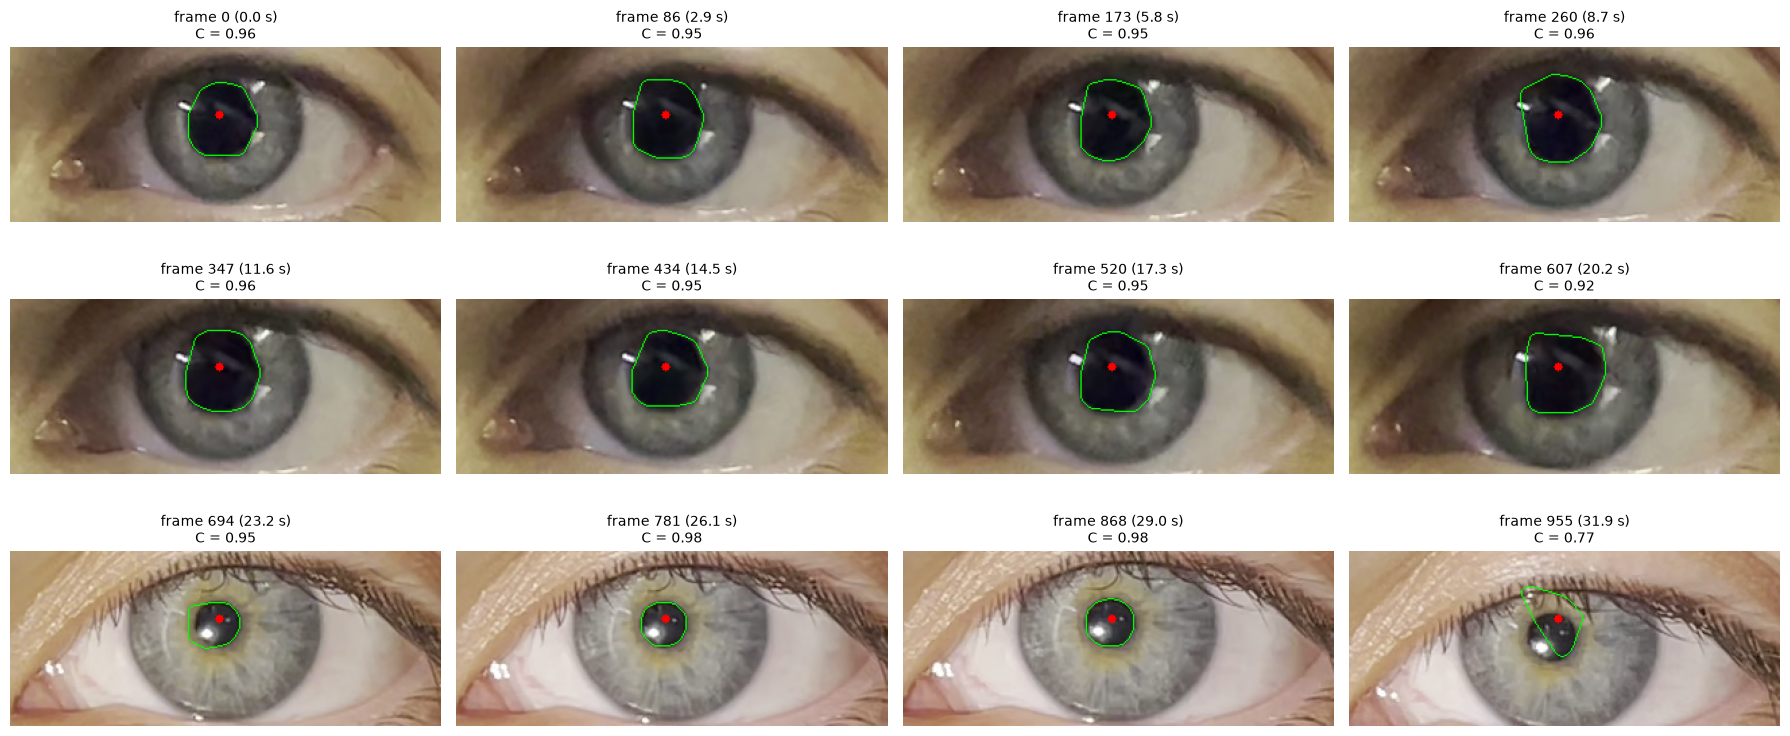

In [136]:
indices = np.linspace(0, n_frames - 1, 12).astype(int)

fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, idx in zip(axs.ravel(), indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap.read()

    centro_i = (int(centros[idx, 0]), int(centros[idx, 1]))
    roi, (cx, cy) = recortar_roi(frame, centro_i)
    gris = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    vis = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

    contorno = medir_pupila(gris, cx=cx, cy=cy)
    if contorno is None:
        titulo = f"frame {idx}: sin segmentación"
    else:
        cv2.drawContours(vis, [contorno], -1, (0, 255, 0), 1)
        titulo = f"frame {idx} ({idx / fps:.1f} s)\nC = {circularidad(contorno):.2f}"
    cv2.circle(vis, (cx, cy), 3, (255, 0, 0), -1)
    ax.imshow(vis); ax.set_title(titulo, fontsize=10); ax.axis("off")
plt.tight_layout()
plt.show()

Se observa que la segmentación planteada se puede generalizar correctamente para los frames del video, con algunas excepciones, como por ejemplo el frame 955, donde posiblemente se encuentren errores de segmentación por parpadeo u otros artefactos.

Para poder estimar si se realizó correctamente la segmentación de un frame, se utiliza el parámetro de circularidad. A continuación se muestra un gráfico de la evolución de este parámetro a lo largo del video.

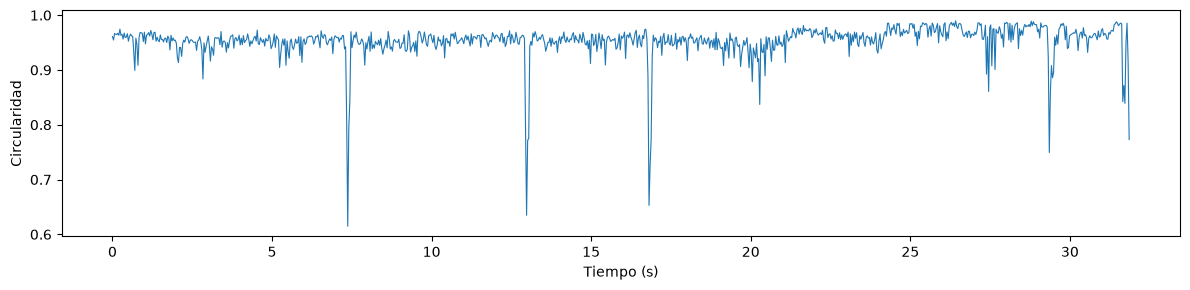

In [137]:
filas = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok or np.isnan(centros[i, 0]):
        filas.append((i, i / fps, np.nan)); continue
    roi, (cx, cy) = recortar_roi(frame, (int(centros[i, 0]), int(centros[i, 1])))
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    filas.append((i, i / fps, np.nan if contorno is None else circularidad(contorno)))

df = pd.DataFrame(filas, columns=["frame", "t (s)", "Circularidad"])

plt.figure(figsize=(12, 3))
plt.plot(df["t (s)"], df["Circularidad"], linewidth=0.8)
plt.xlabel("Tiempo (s)"); plt.ylabel("Circularidad")
plt.tight_layout()
plt.show()

Se observa que la circularidad del contorno tiene leves variaciones a lo largo del video. Los picos y variaciones muy grandes seguramente se deben a parpadeos o movimientos (artefactos). Para el análisis estadístico de algunos parámetros conviene excluir esos frames o interpolar los valores. Para esto, se considerarán frames invalidos a aquellos con un circularidad menor a 0.89, ya que se considera que en esos casos probablemente no se segmentó bien la pupila por algun artefacto.

Frames inválidos: 24 de 956 (2.5 %)


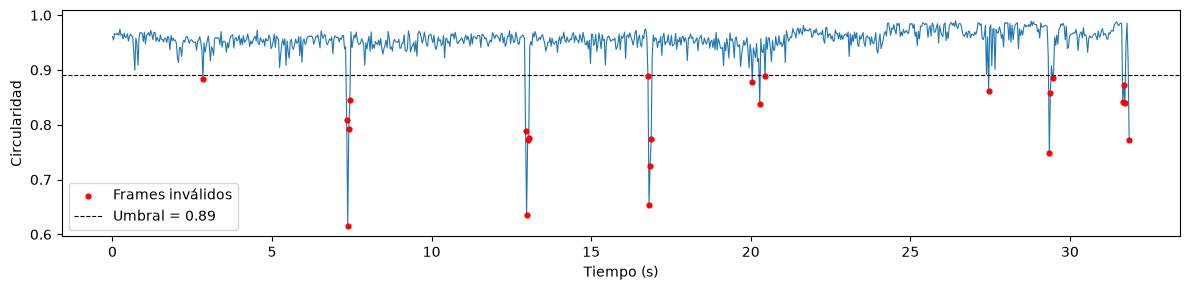

In [138]:
UMBRAL_CIRC = 0.89

df["Válido"] = df["Circularidad"] >= UMBRAL_CIRC     # NaN queda como inválido
print(f"Frames inválidos: {(~df['Válido']).sum()} de {len(df)} "
      f"({100 * (~df['Válido']).mean():.1f} %)")

plt.figure(figsize=(12, 3))
plt.plot(df["t (s)"], df["Circularidad"], linewidth=0.8)
plt.scatter(df.loc[~df["Válido"], "t (s)"], df.loc[~df["Válido"], "Circularidad"],
            color="r", s=12, zorder=3, label="Frames inválidos")
plt.axhline(UMBRAL_CIRC, color="k", linestyle="--", linewidth=0.8, label=f"Umbral = {UMBRAL_CIRC}")
plt.xlabel("Tiempo (s)"); plt.ylabel("Circularidad"); plt.legend()
plt.tight_layout(); plt.show()

A continuación se calculará el área y el diametro frame a frame.

In [140]:
UMBRAL_CIRC = 0.89

filas = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok or np.isnan(centros[i, 0]):
        filas.append((i, i / fps, np.nan, np.nan, np.nan)); continue
    roi, (cx, cy) = recortar_roi(frame, (int(centros[i, 0]), int(centros[i, 1])))
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    if contorno is None:
        filas.append((i, i / fps, np.nan, np.nan, np.nan)); continue
    area = cv2.contourArea(contorno)
    filas.append((i, i / fps, area, 2 * np.sqrt(area / np.pi), circularidad(contorno)))

df = pd.DataFrame(filas, columns=["frame", "t (s)", "Área auto (px²)", "Diámetro auto (px)", "Circularidad"])
df["Válido"] = df["Circularidad"] >= UMBRAL_CIRC            # NaN queda como inválido

df["Área (px²)"] = df["Área auto (px²)"].where(df["Válido"]).interpolate(method="linear", limit_direction="both")
df["Diámetro (px)"] = df["Diámetro auto (px)"].where(df["Válido"]).interpolate(method="linear", limit_direction="both")
df["Interpolado"] = ~df["Válido"]

inv = ~df["Válido"]
rachas = inv.ne(inv.shift()).cumsum()[inv].value_counts()
print(f"Frames interpolados: {inv.sum()} de {len(df)} ({100 * inv.mean():.1f} %) | racha más larga: {rachas.max()} frames ({rachas.max() / fps:.2f} s)")

Frames interpolados: 24 de 956 (2.5 %) | racha más larga: 4 frames (0.13 s)


In [102]:
import os
ANOT_PATH = "../data/reference/anotaciones_manuales.csv"
ESCALA = 4
frames_manual = np.linspace(0, n_frames - 1, 25).astype(int)

def anotar_frame(idx):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, frame = cap.read()
    roi, _ = recortar_roi(frame, (int(centros[idx, 0]), int(centros[idx, 1])))
    grande = cv2.resize(roi, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_CUBIC)
    puntos = []
    def click(ev, x, y, flags, param):
        if ev == cv2.EVENT_LBUTTONDOWN: puntos.append((x, y))
    ventana = f"frame {idx} - clic en el borde (min 5) | Enter: aceptar | u: deshacer | s: saltear"
    cv2.namedWindow(ventana); cv2.setMouseCallback(ventana, click)
    while True:
        vis = grande.copy()
        for p in puntos: cv2.circle(vis, p, 3, (0, 0, 255), -1)
        if len(puntos) >= 5:
            cv2.ellipse(vis, cv2.fitEllipse(np.array(puntos, np.float32)), (0, 255, 0), 1)
        cv2.imshow(ventana, vis)
        k = cv2.waitKey(20) & 0xFF
        if k == 13 and len(puntos) >= 5: break
        if k == ord("u") and puntos: puntos.pop()
        if k == ord("s"): puntos = None; break
    cv2.destroyAllWindows(); cv2.waitKey(1)
    if puntos is None: return None
    (_, _), (d1, d2), _ = cv2.fitEllipse(np.array(puntos, np.float32) / ESCALA)
    area = np.pi * d1 * d2 / 4
    return area, 2 * np.sqrt(area / np.pi)

# Se retoma desde lo que ya esté anotado
manual = pd.read_csv(ANOT_PATH) if os.path.exists(ANOT_PATH) else pd.DataFrame(columns=["frame", "Área manual (px²)", "Diámetro manual (px)"])
for idx in frames_manual:
    if idx in manual["frame"].values: continue
    res = anotar_frame(idx)
    if res is not None:
        manual.loc[len(manual)] = [idx, *res]
        manual.to_csv(ANOT_PATH, index=False)

,n,MAE,RMSE,Sesgo (auto−manual),Error relativo medio (%)
Área (px²),25.0,101.71,142.48,-37.98,5.29
Diámetro (px),25.0,1.26,1.70,-0.30,2.63


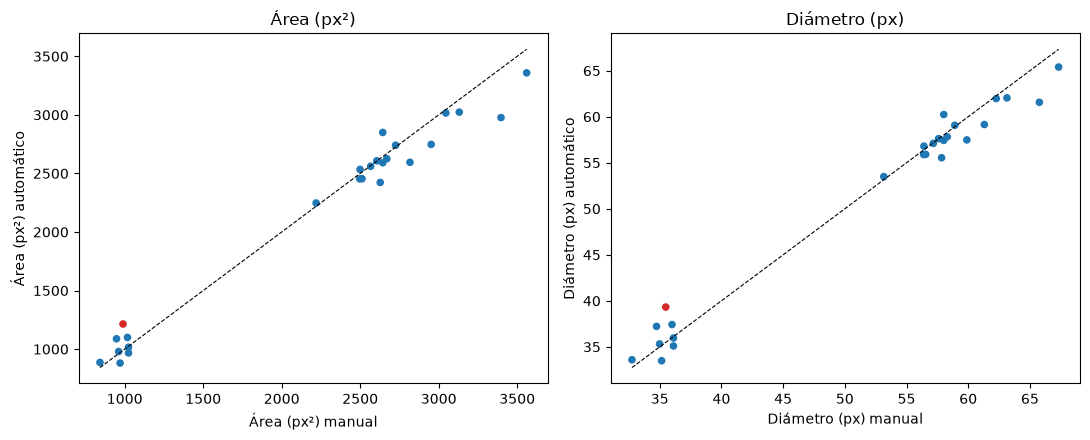

In [134]:
manual = pd.read_csv(ANOT_PATH)
manual = manual[manual["frame"].isin(frames_manual)]
comp = manual.merge(df, on="frame")

def metricas(auto, man):
    e = auto - man
    return {"n": len(e), "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()),
            "Sesgo (auto−manual)": e.mean(), "Error relativo medio (%)": 100 * (e.abs() / man).mean()}

tabla = pd.DataFrame({
    "Área (px²)":    metricas(comp["Área (px²)"], comp["Área manual (px²)"]),
    "Diámetro (px)": metricas(comp["Diámetro (px)"], comp["Diámetro manual (px)"]),
}).T
display(tabla.round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (auto, man, nombre) in zip(axs, [("Área (px²)", "Área manual (px²)", "Área (px²)"),
                                         ("Diámetro (px)", "Diámetro manual (px)", "Diámetro (px)")]):
    ax.scatter(comp[man], comp[auto], c=np.where(comp["Interpolado"], "tab:red", "tab:blue"), s=20)
    lim = [min(comp[man].min(), comp[auto].min()), max(comp[man].max(), comp[auto].max())]
    ax.plot(lim, lim, "k--", linewidth=0.8)
    ax.set_xlabel(f"{nombre} manual"); ax.set_ylabel(f"{nombre} automático"); ax.set_title(nombre)
plt.tight_layout(); plt.show()

La segmentación automática concuerda bien con la medición manual en los 25 frames anotados: el error medio es de 2.6% en el diámetro y de 5.3% en el área, con un sesgo pequeño. El único punto que se aleja de la diagonal corresponde a un frame interpolado. Se considera que la segmentación es adecuada para calcular las curvas temporales.

A continuación se grafican el diámetro D(t) y el área A(t) de la pupila a lo largo del video. En rojo se marcan los frames que se interpolaron.

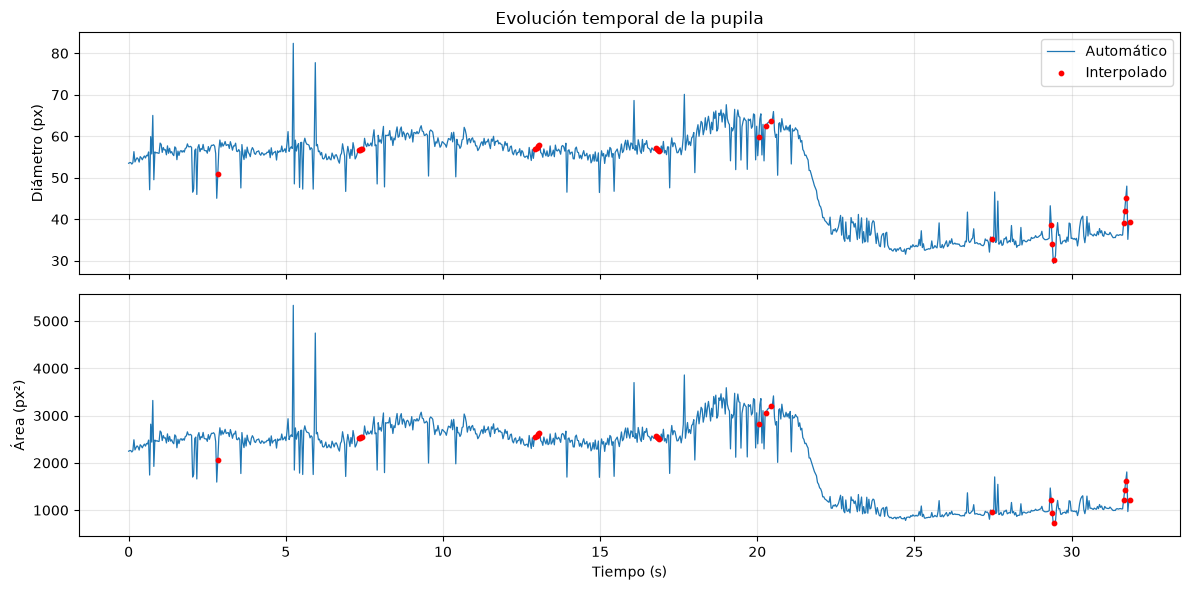

In [143]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, col in [(axs[0], "Diámetro (px)"),
                         (axs[1], "Área (px²)")]:
    ax.plot(df["t (s)"], df[col], linewidth=0.9, label="Automático")
    interp = df[df["Interpolado"]]
    ax.scatter(interp["t (s)"], interp[col], color="r", s=10, zorder=3, label="Interpolado")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

axs[0].legend(loc="upper right")
axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Evolución temporal de la pupila")
plt.tight_layout()
plt.show()

En la curva se observa que el diámetro de la pupila se mantiene en torno a 55–60 px (área de ~2500 px²) durante los primeros ~21 s y luego disminuye de forma marcada, hasta estabilizarse en ~35 px (área de ~1000 px²) a partir de los ~23 s. Esta caída corresponde a la contracción de la pupila. Los picos aislados, probablemente se deban a artefactos u otros ruidos no detectados anteriormente por el criterio de circularidad, como parpadeos o errores puntuales de segmentación.

Para calcular el tiempo de latencia, buscamos el intervalo entre la aplicación del flash y el inicio de la constricción de la pupila.
El instante del estímulo se detecta como el salto de brillo del video, y el inicio de la constricción como el primer instante en que el diámetro cae por debajo de la línea de base previa al estímulo y se mantiene por debajo durante 5 frames consecutivos.

Frame del estímulo: 642 | t = 21.416 s


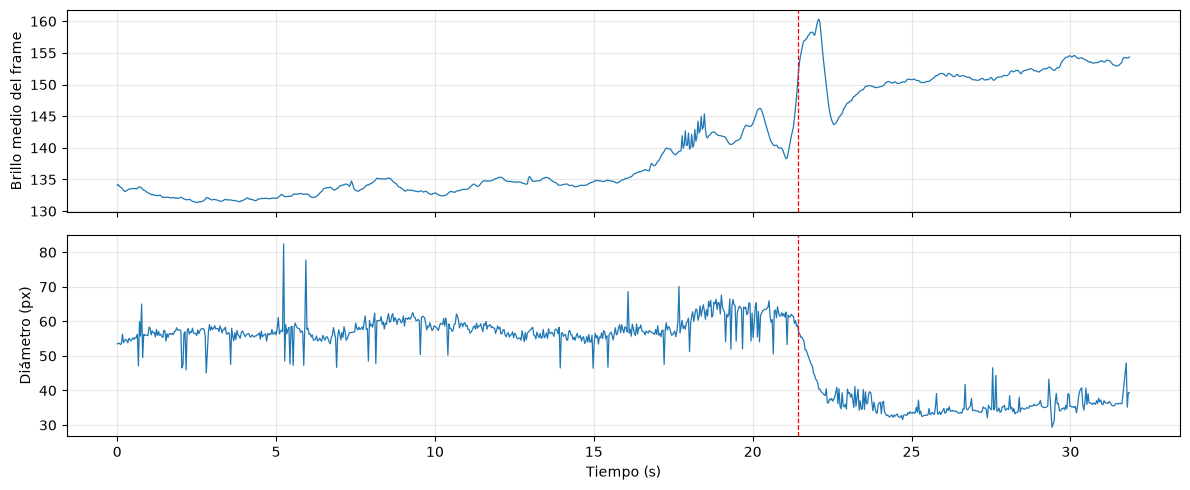

In [146]:
T_ESTIMULO = None

# Brillo medio de cada frame
brillo = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok:
        brillo.append(np.nan); continue
    chico = cv2.resize(frame, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_AREA)
    brillo.append(cv2.mean(cv2.cvtColor(chico, cv2.COLOR_BGR2GRAY))[0])
df["Brillo"] = brillo

b = df["Brillo"].rolling(5, center=True, min_periods=1).median()
salto = b.diff(5).abs()
i_pico = int(salto.idxmax())

base = df["Brillo"].iloc[max(0, i_pico - 60): i_pico - 10]
mu, sd = base.median(), base.std()
umbral = mu + max(3 * sd, 0.05 * (df["Brillo"].iloc[i_pico] - mu))

ini = max(0, i_pico - 15)
i_estimulo = ini + int(np.argmax(df["Brillo"].iloc[ini:i_pico + 1].values > umbral))

if T_ESTIMULO is None:
    T_ESTIMULO = df.loc[i_estimulo, "t (s)"]
print(f"Frame del estímulo: {i_estimulo} | t = {T_ESTIMULO:.3f} s")

# Gráfico general
fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(df["t (s)"], df["Brillo"], linewidth=0.9); axs[0].set_ylabel("Brillo medio del frame")
axs[1].plot(df["t (s)"], df["Diámetro (px)"], linewidth=0.9); axs[1].set_ylabel("Diámetro (px)")
for ax in axs:
    ax.axvline(T_ESTIMULO, color="r", linestyle="--", linewidth=0.9); ax.grid(alpha=0.3)
axs[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

Línea base: 62.3 px (desvío 3.45) | umbral: 52.0 px
Inicio de la constricción: frame 649 (21.649 s)


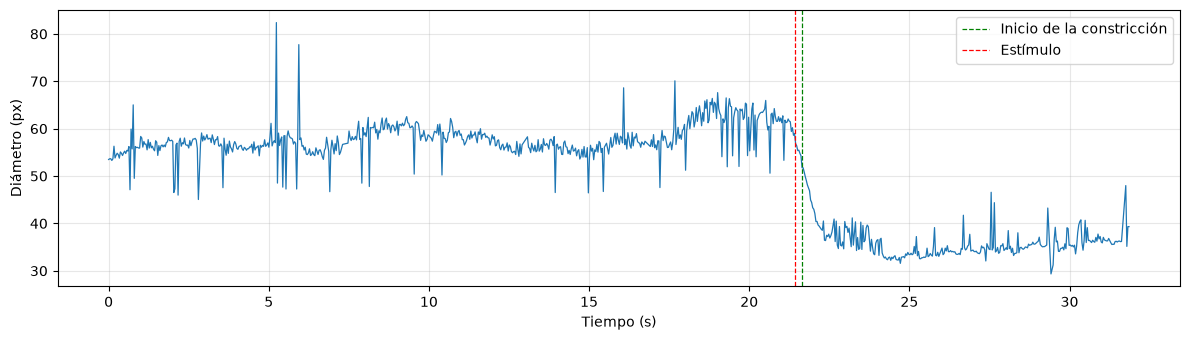

In [150]:
N_SOSTENIDO = 5          # frames consecutivos por debajo de la línea base
VENTANA_BASE_S = 2.0     # segundos previos al estímulo para estimar la línea base
K_SIGMA = 3              # cuántos desvíos por debajo de la base cuenta como "caída"

d = df["Diámetro (px)"].values

# Línea base de diámetro
n_base = int(round(VENTANA_BASE_S * fps))
base_d = d[max(0, i_estimulo - n_base): i_estimulo]
mu_d, sd_d = np.nanmedian(base_d), np.nanstd(base_d)
umbral_d = mu_d - K_SIGMA * sd_d

# Primer frame desde el estímulo
debajo = d < umbral_d
i_constr = None
for i in range(i_estimulo, n_frames - N_SOSTENIDO + 1):
    if debajo[i:i + N_SOSTENIDO].all():
        i_constr = i          
        break

if i_constr is None:
    print("No se detectó constricción sostenida después del estímulo.")

T_CONSTRICCION = df.loc[i_constr, "t (s)"]
print(f"Línea base: {mu_d:.1f} px (desvío {sd_d:.2f}) | umbral: {umbral_d:.1f} px")
print(f"Inicio de la constricción: frame {i_constr} ({T_CONSTRICCION:.3f} s)")

plt.figure(figsize=(12, 3.5))
plt.plot(df["t (s)"], df["Diámetro (px)"], linewidth=0.9)
plt.axvline(T_CONSTRICCION, color="g", linestyle="--", linewidth=0.9, label="Inicio de la constricción")
plt.xlabel("Tiempo (s)"); plt.ylabel("Diámetro (px)")
plt.axvline(T_ESTIMULO, color="r", linestyle="--", linewidth=0.9, label="Estímulo")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [152]:
latencia_s = T_CONSTRICCION - T_ESTIMULO
latencia_frames = i_constr - i_estimulo

print(f"Estímulo:                  frame {i_estimulo} ({T_ESTIMULO:.3f} s)")
print(f"Inicio de la constricción: frame {i_constr} ({T_CONSTRICCION:.3f} s)")
print(f"Tiempo de latencia: {latencia_s * 1000:.0f} ms ({latencia_frames} frames)")

Estímulo:                  frame 642 (21.416 s)
Inicio de la constricción: frame 649 (21.649 s)
Tiempo de latencia: 234 ms (7 frames)


Teniendo en cuenta que la latencia pupilar a un flash en humanos es de 200 a 300 ms en promedio, corroboramos que los resultados obtenidos son lógicos.

Área basal:  3071 px²
Área mínima: 832 px² (frame 734, 24.48 s)
Amplitud de respuesta: 2238 px² (72.9 % del área basal)


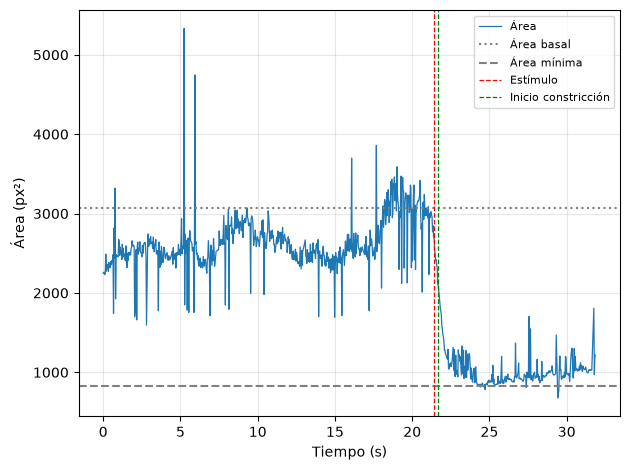

In [163]:
VENT_MIN = 15      # frames de la mediana móvil (descarta picos aislados)

a = df["Área (px²)"]
a_suav = a.rolling(VENT_MIN, center=True, min_periods=1).median()

# Área basal: mediana de la serie suavizada en la ventana previa al estímulo (oscuridad)
area_basal = a_suav.iloc[max(0, i_estimulo - n_base): i_estimulo].median()

# Área mínima: mínimo de la serie suavizada desde el inicio de la constricción
i_min = int(a_suav.iloc[i_constr:].idxmin())
area_min = a_suav.iloc[i_min]
t_min = df.loc[i_min, "t (s)"]

# Amplitud de respuesta
amplitud = area_basal - area_min
amplitud_pct = 100 * amplitud / area_basal

print(f"Área basal:  {area_basal:.0f} px²")
print(f"Área mínima: {area_min:.0f} px² (frame {i_min}, {t_min:.2f} s)")
print(f"Amplitud de respuesta: {amplitud:.0f} px² ({amplitud_pct:.1f} % del área basal)")

# Gráfico
plt.plot(df["t (s)"], a, linewidth=0.9, label="Área")
plt.axhline(area_basal, color="gray", ls=":", label=f"Área basal")
plt.axhline(area_min, color="gray", ls="--", label=f"Área mínima")
plt.axvline(T_ESTIMULO, color="r", ls="--", linewidth=0.9, label="Estímulo")
plt.axvline(T_CONSTRICCION, color="g", ls="--", linewidth=0.9, label="Inicio constricción")
plt.xlabel("Tiempo (s)"); plt.ylabel("Área (px²)")
plt.legend(loc="upper right", fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cabe aclarar que todos los valores de área y diámetro están expresados en píxeles, no en unidades físicas. Por eso no es del todo seguro guiarse por los valores absolutos: si durante la toma la cámara se acercó o se alejó del ojo, o el ojo cambió de distancia respecto de ella, el tamaño aparente de la pupila en la imagen pudo variar y modificar los resultados, sin que eso corresponda a un cambio real de la pupila.

A continuación, calcularemos la velocidad media de constricción, que se obtiene como el cambio total entre el inicio de la constricción y el mínimo, dividido por el tiempo que tardó.

In [166]:
FRAC_CAIDA = 0.9   # fracción de la caída total que marca el final de la constricción

def constriccion(serie):
    s = serie.rolling(VENT_MIN, center=True, min_periods=1).median()
    base = s.iloc[max(0, i_estimulo - n_base): i_estimulo].median()
    minimo = s.iloc[i_constr:].min()
    nivel = base - FRAC_CAIDA * (base - minimo)
    i_fin = i_constr + int(np.argmax(s.iloc[i_constr:].values <= nivel))   # primer frame que llega al 90 % de la caída
    return s, base, minimo, i_fin

def velocidad_media_constriccion(serie, unidad):
    s, base, minimo, i_fin = constriccion(serie)
    dur = df.loc[i_fin, "t (s)"] - T_CONSTRICCION
    vel = (base - s.iloc[i_fin]) / dur
    return pd.DataFrame({
        f"Basal ({unidad})": [base],
        f"Mínimo ({unidad})": [minimo],
        "Duración (s)": [dur],
        f"Velocidad media ({unidad}/s)": [vel],
    }, index=[""])

display(velocidad_media_constriccion(df["Diámetro (px)"], "px").round(2))

,Basal (px),Mínimo (px),Duración (s),Velocidad media (px/s)
,62.53,32.56,2.34,11.81


Se obtiene una velocidad de constricción de 11,81 px/s.

Para calcular la velocidad de redilatación se utiliza otro video. Repetimos todo el procesamiento aplicado al primer video para poder obtener los datos.

FPS: 29.98 | Frames: 615 | Duración: 20.52 s


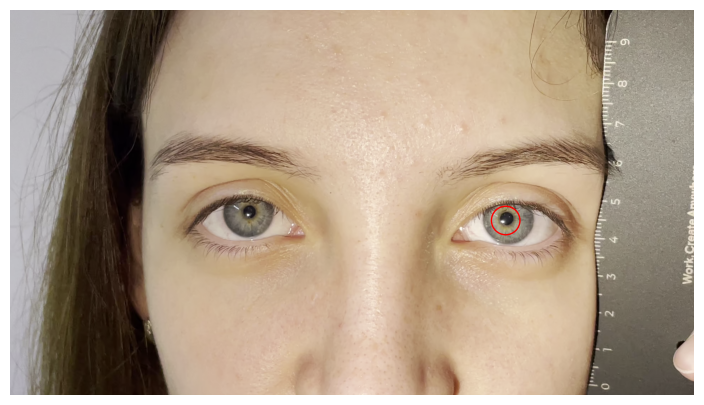

In [179]:
VIDEO_PATH_2 = "../data/raw/Registro B_1.MOV"

cap2 = cv2.VideoCapture(VIDEO_PATH_2)
if not cap2.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH_2}")
fps2 = cap2.get(cv2.CAP_PROP_FPS)
n_frames2 = int(cap2.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps2:.2f} | Frames: {n_frames2} | Duración: {n_frames2 / fps2:.2f} s")

CENTRO_INICIAL_2 = (1390, 590)
RADIO_INICIAL_2 = 40

cap2.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame0 = cap2.read()
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB))
plt.plot(*CENTRO_INICIAL_2, "r", ms=15)
plt.gca().add_patch(plt.Circle(CENTRO_INICIAL_2, RADIO_INICIAL_2, fill=False, color="r"))
plt.axis("off"); plt.show()

In [180]:
UMBRAL_CIRC = 0.89

def procesar_video(cap_v, n_v, fps_v, centro_inicial, radio_inicial):
    centros_v, centro = [], centro_inicial
    cap_v.set(cv2.CAP_PROP_POS_FRAMES, 0)
    for i in range(n_v):
        ok, frame = cap_v.read()
        if not ok:
            centros_v.append((np.nan, np.nan)); continue
        centro = seguir_pupila(frame, centro, radio_inicial if i == 0 else RADIO_BUSQUEDA)
        centros_v.append(centro)
    centros_v = np.array(centros_v, dtype=float)

    # 2) Medición frame a frame
    filas = []
    cap_v.set(cv2.CAP_PROP_POS_FRAMES, 0)
    for i in range(n_v):
        ok, frame = cap_v.read()
        if not ok or np.isnan(centros_v[i, 0]):
            filas.append((i, i / fps_v, np.nan, np.nan, np.nan)); continue
        roi, (cx, cy) = recortar_roi(frame, (int(centros_v[i, 0]), int(centros_v[i, 1])))
        contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
        if contorno is None:
            filas.append((i, i / fps_v, np.nan, np.nan, np.nan)); continue
        area = cv2.contourArea(contorno)
        filas.append((i, i / fps_v, area, 2 * np.sqrt(area / np.pi), circularidad(contorno)))

    d = pd.DataFrame(filas, columns=["frame", "t (s)", "Área auto (px²)", "Diámetro auto (px)", "Circularidad"])
    d["Válido"] = d["Circularidad"] >= UMBRAL_CIRC
    d["Área (px²)"] = d["Área auto (px²)"].where(d["Válido"]).interpolate(method="linear", limit_direction="both")
    d["Diámetro (px)"] = d["Diámetro auto (px)"].where(d["Válido"]).interpolate(method="linear", limit_direction="both")
    d["Interpolado"] = ~d["Válido"]
    return d, centros_v

df2, centros2 = procesar_video(cap2, n_frames2, fps2, CENTRO_INICIAL_2, RADIO_INICIAL_2)

inv = ~df2["Válido"]
rachas = inv.ne(inv.shift()).cumsum()[inv].value_counts()
print(f"Frames interpolados: {inv.sum()} de {len(df2)} ({100 * inv.mean():.1f} %) | "
      f"racha más larga: {rachas.max()} frames ({rachas.max() / fps2:.2f} s)")

Frames interpolados: 8 de 615 (1.3 %) | racha más larga: 4 frames (0.13 s)


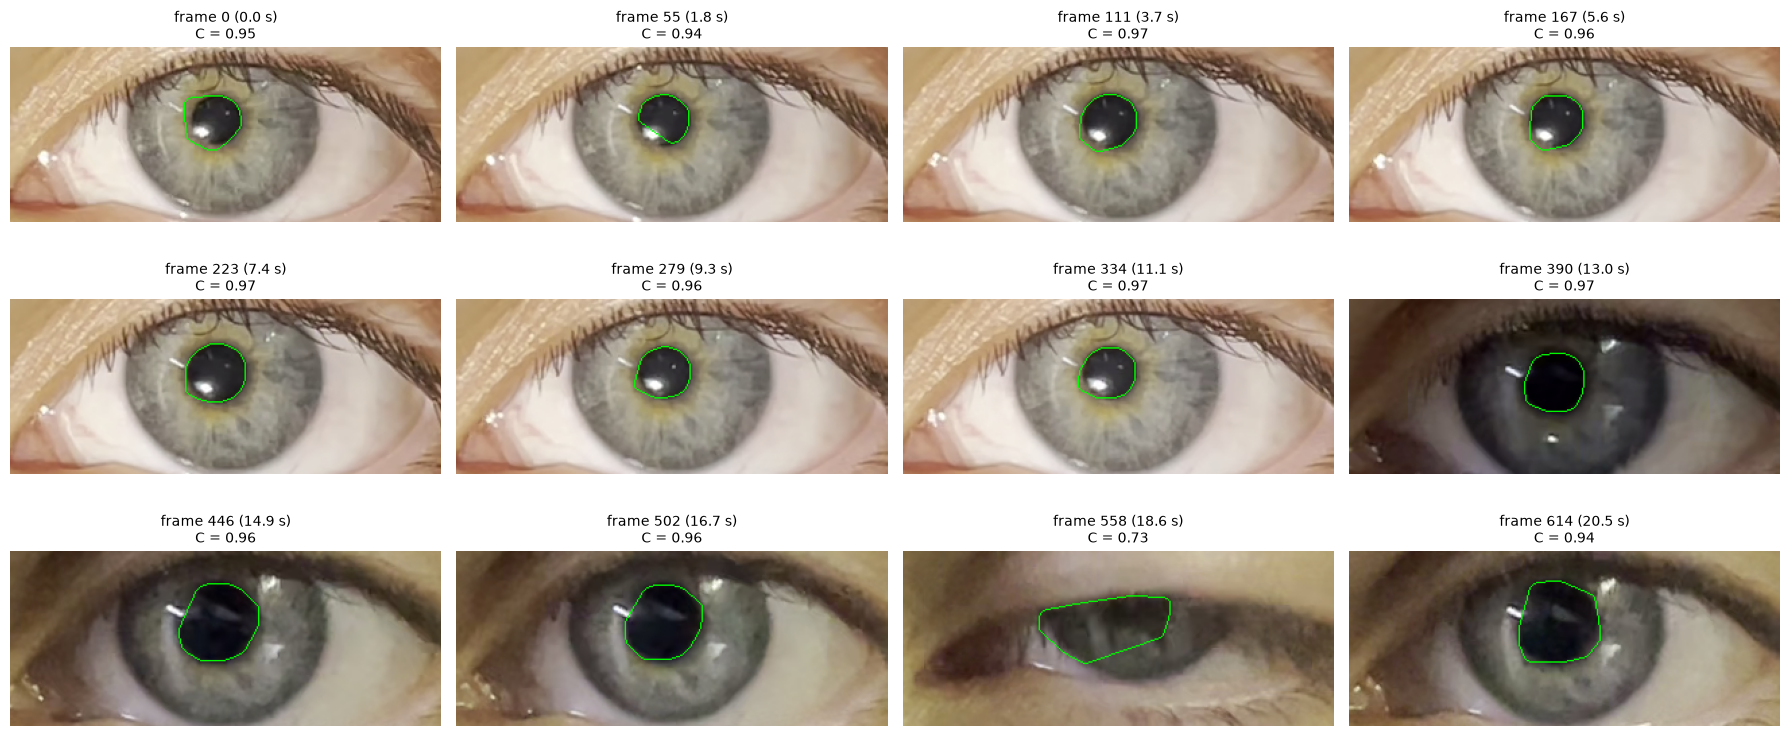

In [181]:
indices = np.linspace(0, n_frames2 - 1, 12).astype(int)

fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, idx in zip(axs.ravel(), indices):
    cap2.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap2.read()
    roi, (cx, cy) = recortar_roi(frame, (int(centros2[idx, 0]), int(centros2[idx, 1])))
    vis = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    if contorno is None:
        titulo = f"frame {idx}: sin segmentación"
    else:
        cv2.drawContours(vis, [contorno], -1, (0, 255, 0), 1)
        titulo = f"frame {idx} ({idx / fps2:.1f} s)\nC = {circularidad(contorno):.2f}"
    ax.imshow(vis); ax.set_title(titulo, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

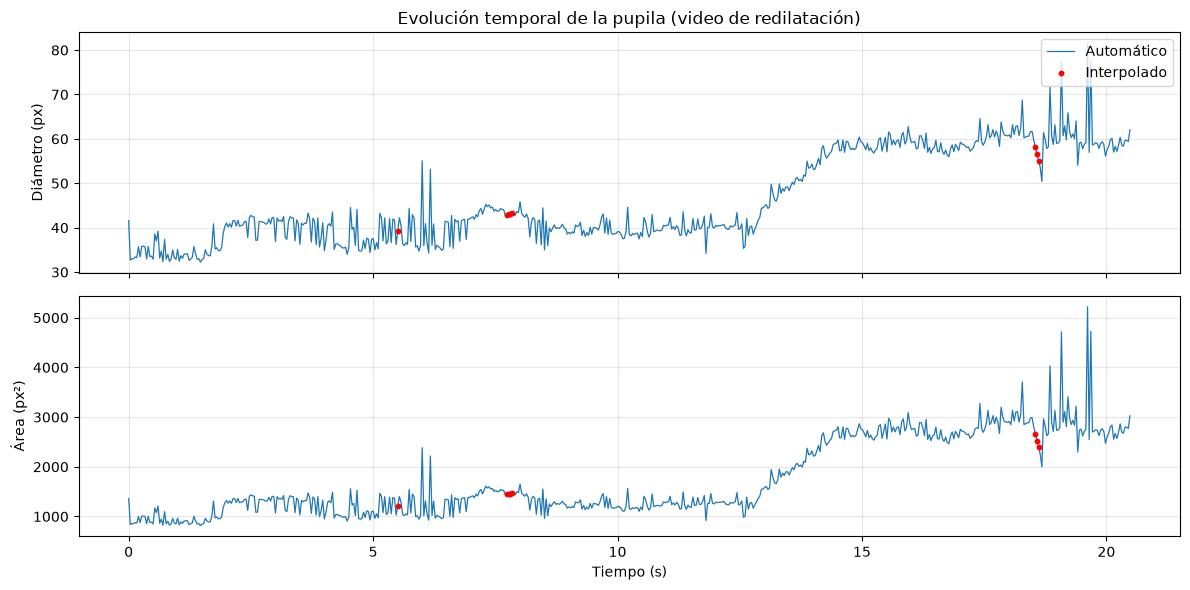

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col in [(axs[0], "Diámetro (px)"), (axs[1], "Área (px²)")]:
    ax.plot(df2["t (s)"], df2[col], linewidth=0.9, label="Automático")
    interp = df2[df2["Interpolado"]]
    ax.scatter(interp["t (s)"], interp[col], color="r", s=10, zorder=3, label="Interpolado")
    ax.set_ylabel(col); ax.grid(alpha=0.3)
axs[0].legend(loc="upper right"); axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Evolución temporal de la pupila")
plt.tight_layout(); plt.show()

In [185]:
N_SOSTENIDO = 5
VENTANA_BASE_S = 2.0
K_SIGMA = 3
VENT_MIN = 15
FRAC_SUBIDA = 0.9      # fracción de la subida total que marca el final de la redilatación
T_REF = (9, 12)

n_base2 = int(round(VENTANA_BASE_S * fps2))
t2 = df2["t (s)"].values
m_ref = (t2 >= T_REF[0]) & (t2 <= T_REF[1])
i_ref_fin = int(np.where(m_ref)[0][-1])

# Mínimo de la serie suavizada (descarta picos aislados) y su ruido
s_dia2 = df2["Diámetro (px)"].rolling(VENT_MIN, center=True, min_periods=1).median().values
mu_c, sd_c = np.median(s_dia2[m_ref]), np.std(s_dia2[m_ref])
umbral_up = mu_c + K_SIGMA * sd_c

encima = s_dia2 > umbral_up
i_red = None
for i in range(i_ref_fin, n_frames2 - N_SOSTENIDO + 1):
    if encima[i:i + N_SOSTENIDO].all():
        i_red = i              # primer frame de la racha, no el último
        break
if i_red is None:
    raise RuntimeError("No se detectó redilatación sostenida después de la ventana de referencia.")
T_REDILATACION = df2.loc[i_red, "t (s)"]
print(f"Nivel previo: {mu_c:.1f} px (desvío {sd_c:.2f}) | umbral: {umbral_up:.1f} px")
print(f"Inicio de la redilatación: frame {i_red} ({T_REDILATACION:.3f} s)")

# Velocidad media
def redilatacion(serie):
    s = serie.rolling(VENT_MIN, center=True, min_periods=1).median()
    previo = s[m_ref].median()
    final = s.iloc[-n_base2:].median()
    if final <= previo:
        raise RuntimeError("El nivel final no es mayor que el nivel previo: revisar la señal.")
    nivel = previo + FRAC_SUBIDA * (final - previo)
    i_fin = i_red + int(np.argmax(s.iloc[i_red:].values >= nivel))   # primer frame que llega al 90 % de la subida
    return s, previo, final, i_fin

def velocidad_media_redilatacion(serie, unidad):
    s, previo, final, i_fin = redilatacion(serie)
    dur = df2.loc[i_fin, "t (s)"] - T_REDILATACION
    vel = (s.iloc[i_fin] - previo) / dur
    return pd.DataFrame({
        f"Nivel previo ({unidad})": [previo],
        f"Nivel final ({unidad})": [final],
        "Duración (s)": [dur],
        f"Velocidad media ({unidad}/s)": [vel],
    }, index=[""])

print("DIÁMETRO")
display(velocidad_media_redilatacion(df2["Diámetro (px)"], "px").round(2))

Nivel previo: 39.5 px (desvío 0.54) | umbral: 41.1 px
Inicio de la redilatación: frame 385 (12.843 s)
DIÁMETRO


,Nivel previo (px),Nivel final (px),Duración (s),Velocidad media (px/s)
,39.52,59.06,1.47,12.05


Se obtiene una velocidad de redilatación de 12,05 px/s. Los dos valores de velocidades son practicamente iguales, solo hay un ~2% de diferencia entre ellos, lo que está dentro de la incertidumbre de la medición.
Cabe aclarar que la constricción suele ser más rápida que la redilatación. Acá no se observa esa diferencia, y puede deberse a posibles cambios de escala de la cámara entre tomas, y que se está haciendo el cálculo a partir de una sola medición, sin poder evaluar errores a partir del análisis de otros videos.

En cuanto a presencia de artefactos, se implementaron los siguientes métodos a lo largo del análisis para poder filtrarlos e interpolarlos:
- Movimientos oculares y de cabeza: la pupila se sigue frame a frame con una ventana de búsqueda centrada en su posición del frame anterior, y la ROI se recorta centrada en ese punto, de modo que el movimiento no desplaza la pupila fuera del análisis.
- Reflejos del flash: los píxeles muy brillantes cercanos a la pupila se detectan, se dilatan y se rellenan con los píxeles de alrededor. Además, se aplica una apertura morfológica y un suavizado gaussiano que eliminan reflejos y pestañas.
- Pestañas y sombras sobre el borde: en la segmentación por Watershed se prueban tres radios de marcador y se elige el contorno con mayor contraste de borde. Luego se aplican una apertura de 11×11, un cierre de 21×21 y la envolvente convexa.

- Para cada frame se calcula la circularidad del contorno. Se consideran inválidos los frames con circularidad < 0,89 y aquellos donde no se pudo segmentar la pupila, que pudo haber sido por parpadeos o errores puntuales de segmentación. Cabe aclarar que este umbral se eligió observando solo el primer video analizado.
- Los valores de área y diámetro de los frames inválidos se reemplazan por interpolación lineal entre los frames válidos vecinos.